In [16]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pickle
import time
from deep_bsde_model import DeepBSDE
from sampling import call_payoff, eu_call_price, basket_call_payoff, y0_init
from functools import partial
import os 

r = 0.05  # interest rate
sigma = 0.2  # volatility
T = 1.0  # maturity<
N = 30 #standard time discretization
K = 100.0

We create a test comparing deep BSDE against the closed form BS call price

In [ ]:
#we train the model for multiple strikes
K = np.linspace(50,150, 5)
models = []
for k in K:
    print(f'strike price is {k}')
    mu_fn = lambda t, x: r * x
    f_fn = lambda t, x, y, z: -r * y
    sigma_const = tf.constant(sigma, dtype=tf.float32)
    sigma_fn = lambda t, x: sigma_const * x
    payoff_fn = partial(call_payoff, K=k)

    X_low, X_high = 80,120 
    model = DeepBSDE(d=1, N=N, X0_low=X_low, X0_high=X_high, mu_fn=mu_fn, sigma_fn=sigma_fn, f_fn=f_fn , 
                     payoff_fn=payoff_fn, num_units=10, num_hidden_layers=3, verbose=2
                    )
    model.train(num_epochs= 2000, batch_size=256)
    print('-'*50)
    print(f'model for k={k} finnished training')
    models.append(model)

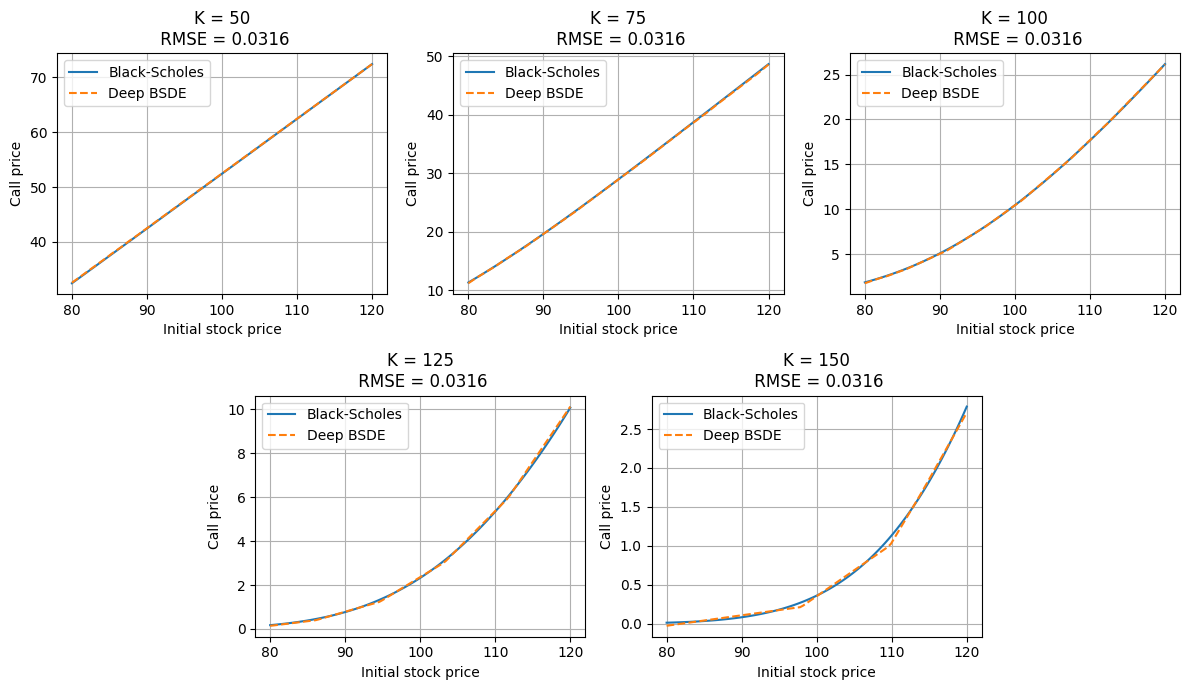

In [29]:
fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 6)
S0_points = np.linspace(80, 120, 100)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[0, 4:6]),
    fig.add_subplot(gs[1, 1:3]),
    fig.add_subplot(gs[1, 3:5])
]

for i, (k, model) in enumerate(zip(K, models)):

    bsde_prices = model.predict_price(
        S0_points.reshape(-1, 1)
    ).numpy()

    bs_prices = eu_call_price(
        S0_points, k, T, r, sigma
    )

    axes[i].plot(S0_points, bs_prices, label="Black-Scholes")
    axes[i].plot(S0_points, bsde_prices, "--", label="Deep BSDE")

    axes[i].set_title(f"K = {k:.0f}\n RMSE = {rmse:.4f}")
    axes[i].set_xlabel("Initial stock price")
    axes[i].set_ylabel("Call price")
    axes[i].legend()
    axes[i].grid(True)

plt.tight_layout()

fig.savefig("images/deep_bsde_vs_bs_d1.pdf", bbox_inches="tight")
plt.show()

In [ ]:
dims = [2, 3, 5, 10, 20, 50, 100]
K, T, r = 100, 1.0, 0.05
N, num_epochs, batch_size = 20, 3000, 1024

os.makedirs("./sweep_checkpoints", exist_ok=True)
models = {}

for d in dims:
    print(f"\nTraining d={d}")
    t0 = time.time()
    sigma = np.full(d, 0.2, dtype=np.float32)
    weights = np.ones(d, dtype=np.float32) / d
    corr = np.full((d, d), 0.3, dtype=np.float32)
    np.fill_diagonal(corr, 1.0)

    mu_fn = lambda t, x: r * x
    f_fn = lambda t, x, y, z: -r * y
    sigma_fn = lambda t, x: tf.constant(sigma) * x
    payoff_fn = partial(basket_call_payoff, K=K, weights=weights)

    model = DeepBSDE(
        d=d, N=N,
        X0_low=np.full(d, 80, dtype=np.float32),
        X0_high=np.full(d, 120, dtype=np.float32),
        payoff_fn=payoff_fn,
        mu_fn=mu_fn,
        sigma_fn=sigma_fn,
        f_fn=f_fn,
        T=T, rho=corr, verbose = 2
    )

    model.train(num_epochs=num_epochs, batch_size=batch_size)
    train_time = t0 - time.time()
    models[d] = (model, train_time)

    model.save_weights(f"./sweep_checkpoints/model_d{d}.weights.h5")


In [ ]:
maes, rmses = [], []
M, mc_batch = 200, 100_000
mc_maes, mc_rmses = [], []

for d, item in models.items():
    print(f"Evaluating d={d}")
    model = item[0]
    runtime = item[1]
    rng = np.random.default_rng(d)
    X_test = rng.uniform(80, 120, size=(M, d)).astype(np.float32)

    predictions = model.predict_price(X_test).numpy()

    corr = np.full((d, d), 0.3, dtype=np.float32)
    np.fill_diagonal(corr, 1.0)

    mc_prices, mc_errors = np.array([
        y0_init(
            x, K, T, r=r, sigma=0.2,
            weights=np.ones(d, dtype=np.float32) / d,
            corr=corr, batch_size=mc_batch
        )
        for x in X_test
    ])

    mc_maes.append(np.sqrt(2 / np.pi) * np.mean(mc_errors))
    mc_rmses.append(np.sqrt(np.mean(mc_errors**2)))

    errors = predictions - mc_prices
    maes.append(np.mean(np.abs(errors)))
    rmses.append(np.sqrt(np.mean(errors**2)))

Evaluating d=2
Evaluating d=3
Evaluating d=5
Evaluating d=10
Evaluating d=20
Evaluating d=50
Evaluating d=100


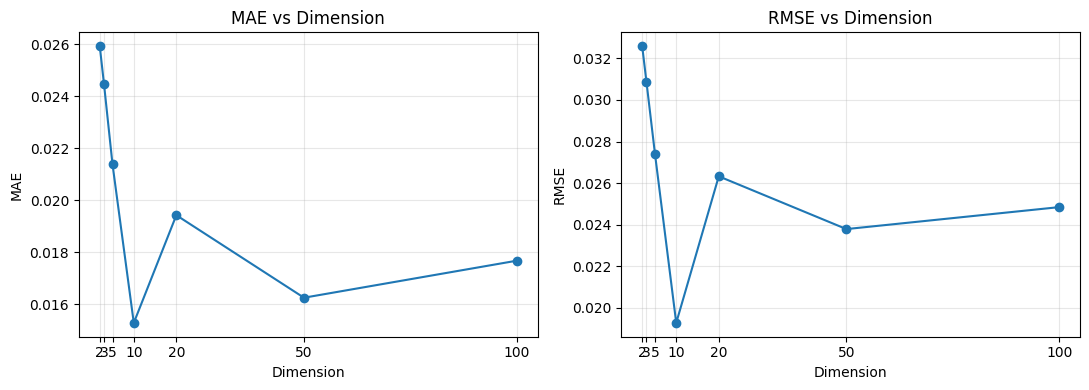

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(dims, maes, "o-")
axes[0].set(xlabel="Dimension", ylabel="MAE", title="MAE vs Dimension")

axes[1].plot(dims, rmses, "o-")
axes[1].set(xlabel="Dimension", ylabel="RMSE", title="RMSE vs Dimension")

axes[0].plot(dims, mc_maes, "--", label="MC noise floor")
axes[1].plot(dims, mc_rmses, "--", label="MC noise floor")

for ax in axes:
    ax.grid(True, alpha=0.3)
    ax.set_xticks(dims)

plt.tight_layout()
plt.show()